Original Data:
            Total_Sales
Date                   
2007-01-01        12685
2007-02-01         9793
2007-03-01        11264
2007-04-01         8854
2007-05-01        12007


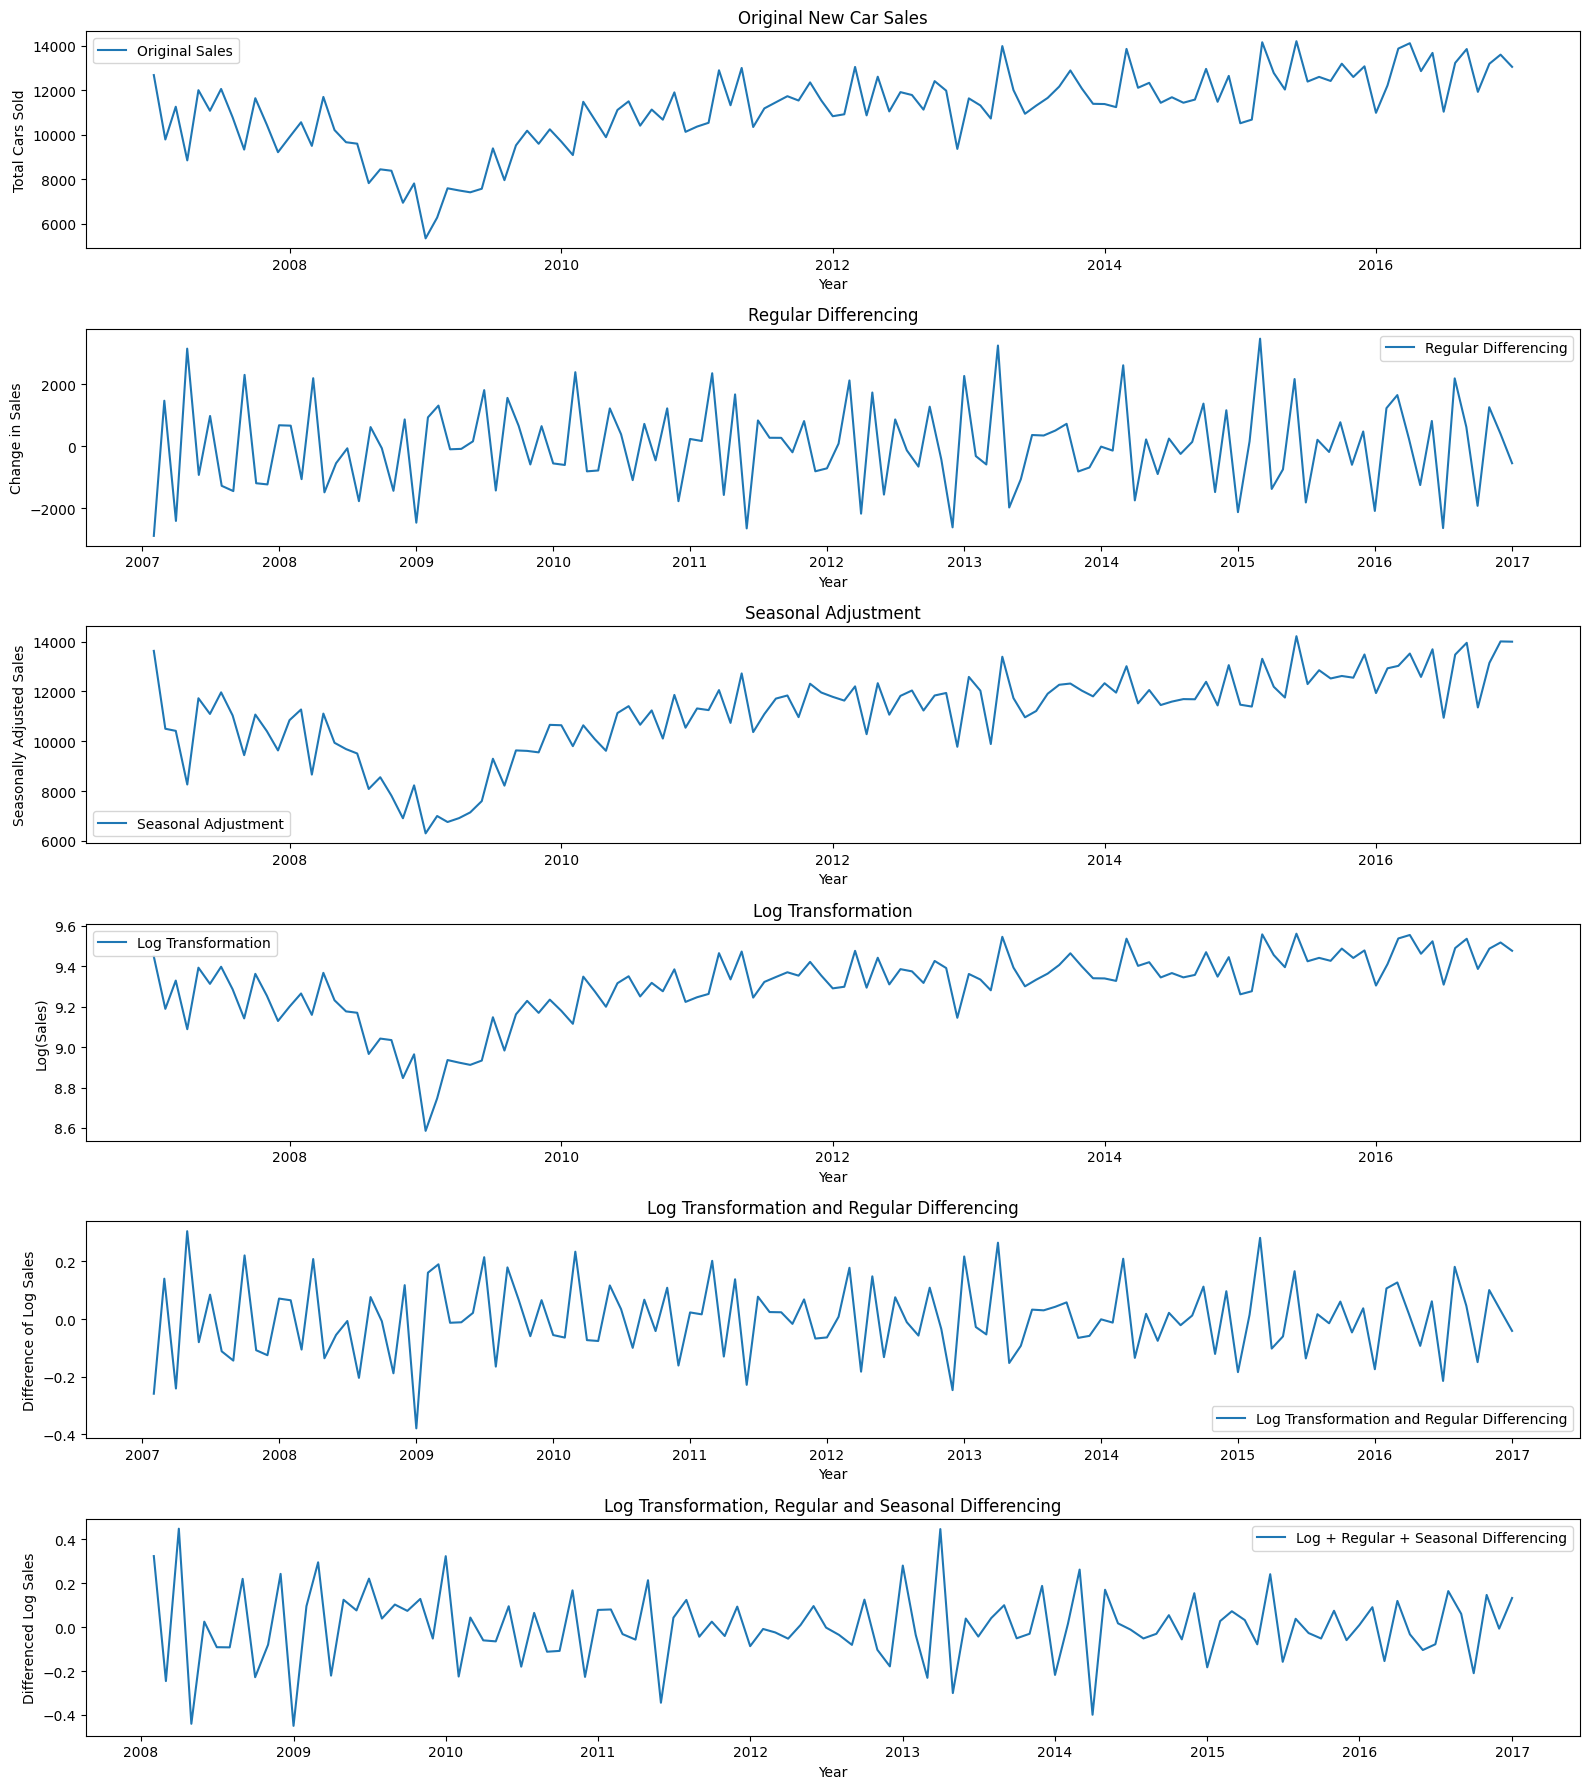

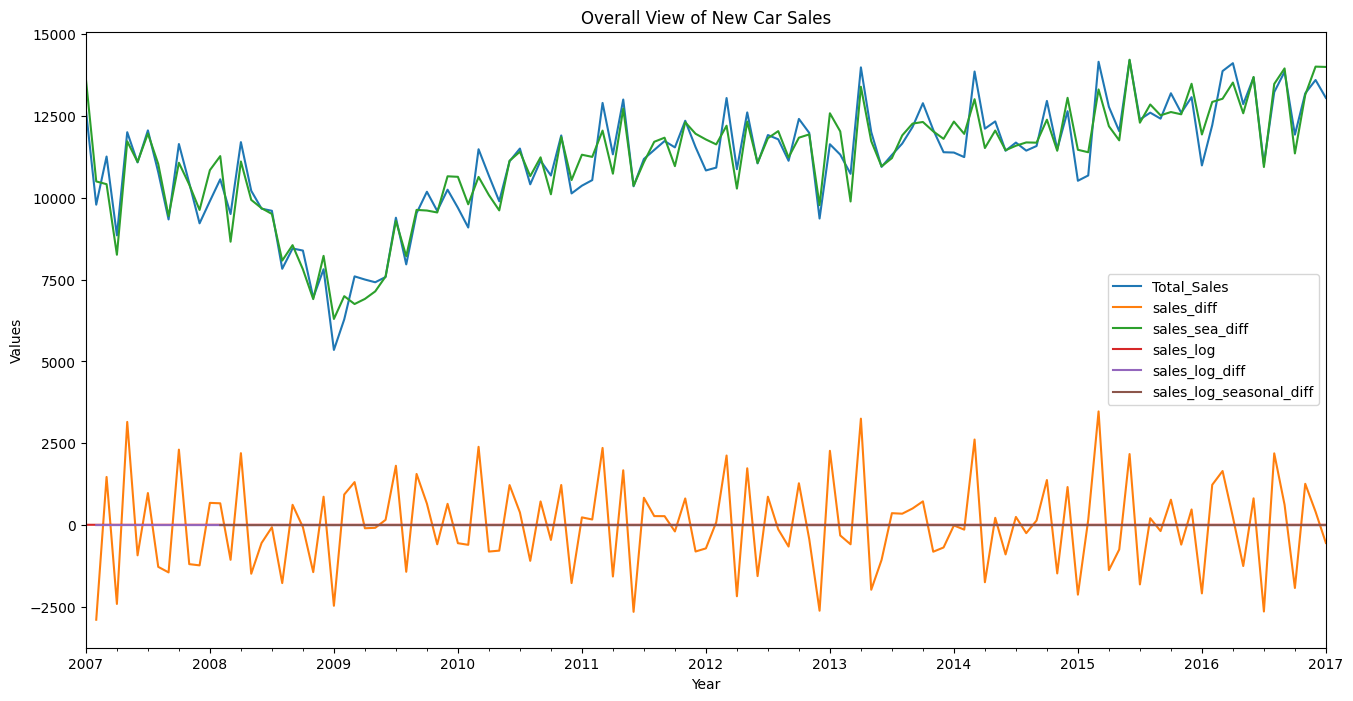


Overall Results:
            Total_Sales  sales_diff  sales_sea_diff  sales_log  \
Date                                                             
2016-09-01        13854       622.0    13956.085185   9.536329   
2016-10-01        11932     -1922.0    11358.312037   9.386979   
2016-11-01        13194      1262.0    13147.974074   9.487517   
2016-12-01        13602       408.0    14011.191667   9.517972   
2017-01-01        13055      -547.0    14001.376852   9.476926   

            sales_log_diff  sales_log_seasonal_diff  
Date                                                 
2016-09-01        0.045936                 0.060561  
2016-10-01       -0.149350                -0.209951  
2016-11-01        0.100538                 0.146831  
2016-12-01        0.030455                -0.006780  
2017-01-01       -0.041046                 0.132809  

Dataset Information:
Total Months: 121
Total Car Manufacturers: 65
Total Cars Sold: 1347250


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose

data = pd.read_csv('/content/New Car Sales by Make.csv')

data['Date'] = pd.to_datetime(dict(
    year=data['Year'],
    month=data['Month'],
    day=1
))

monthly_sales = data.groupby('Date')['Quantity'].sum().sort_index()

monthly_sales = monthly_sales.asfreq('MS')

data_ts = pd.DataFrame(monthly_sales)
data_ts.columns = ['Total_Sales']

print("Original Data:")
print(data_ts.head())

data_ts['sales_diff'] = data_ts['Total_Sales'].diff()

result = seasonal_decompose(
    data_ts['Total_Sales'],
    model='additive',
    period=12
)

data_ts['sales_sea_diff'] = (
    data_ts['Total_Sales'] - result.seasonal
)

data_ts['sales_log'] = np.log(data_ts['Total_Sales'])

data_ts['sales_log_diff'] = (
    data_ts['sales_log'].diff()
)

data_ts['sales_log_seasonal_diff'] = (
    data_ts['sales_log_diff'].diff(12)
)

plt.figure(figsize=(16, 18))

plt.subplot(6, 1, 1)
plt.plot(data_ts['Total_Sales'], label='Original Sales')
plt.legend(loc='best')
plt.title('Original New Car Sales')
plt.xlabel('Year')
plt.ylabel('Total Cars Sold')

plt.subplot(6, 1, 2)
plt.plot(data_ts['sales_diff'], label='Regular Differencing')
plt.legend(loc='best')
plt.title('Regular Differencing')
plt.xlabel('Year')
plt.ylabel('Change in Sales')

plt.subplot(6, 1, 3)
plt.plot(data_ts['sales_sea_diff'], label='Seasonal Adjustment')
plt.legend(loc='best')
plt.title('Seasonal Adjustment')
plt.xlabel('Year')
plt.ylabel('Seasonally Adjusted Sales')

plt.subplot(6, 1, 4)
plt.plot(data_ts['sales_log'], label='Log Transformation')
plt.legend(loc='best')
plt.title('Log Transformation')
plt.xlabel('Year')
plt.ylabel('Log(Sales)')

plt.subplot(6, 1, 5)
plt.plot(data_ts['sales_log_diff'],
         label='Log Transformation and Regular Differencing')
plt.legend(loc='best')
plt.title('Log Transformation and Regular Differencing')
plt.xlabel('Year')
plt.ylabel('Difference of Log Sales')

plt.subplot(6, 1, 6)
plt.plot(data_ts['sales_log_seasonal_diff'],
         label='Log + Regular + Seasonal Differencing')
plt.legend(loc='best')
plt.title('Log Transformation, Regular and Seasonal Differencing')
plt.xlabel('Year')
plt.ylabel('Differenced Log Sales')

plt.tight_layout()
plt.show()

data_ts.plot(
    kind='line',
    figsize=(16, 8),
    title='Overall View of New Car Sales'
)

plt.xlabel('Year')
plt.ylabel('Values')
plt.show()

print("\nOverall Results:")
print(data_ts.tail())

print("\nDataset Information:")
print("Total Months:", len(data_ts))
print("Total Car Manufacturers:", data['Make'].nunique())
print("Total Cars Sold:", data['Quantity'].sum())
